# Macroeconomic Baseline Models: GDP, Inflation, and CPI

This notebook prepares a small annual dataset from three sheets in the supplied Bangladesh macroeconomic workbook and compares three straightforward baseline models:

- **Table IXC:** quarterly GDP at current prices, aggregated to fiscal-year GDP
- **Table IB:** CPI, inflation, industrial production, imports, reserves, and exchange rates
- **Table IV:** annual merchandise exports

**Targets:** GDP, 12-month average inflation rate, and point-to-point CPI.

The notebook is designed to run from top to bottom. Keep the Excel workbook in the same folder as this notebook, or in its parent folder; otherwise update `WORKBOOK_FILE` in the setup cell.

## Important scope note

The merged dataset contains only a small number of annual observations. The model results are therefore **exploratory baseline comparisons**, not reliable forecasts. The final two fiscal years are held out for a chronological test; all three targets are excluded from the predictors to avoid target leakage.

Some workbook periods are marked **P** (provisional). The notebook keeps these observations but removes the `P` suffix only for consistent fiscal-year matching.

## 1. Import libraries

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

## 2. Load the workbook

In [2]:
WORKBOOK_FILE = "Apr26 (For Shounok 16.07.2026).xlsx"

workbook_candidates = [
    Path(WORKBOOK_FILE),
    Path.cwd().parent / WORKBOOK_FILE,
]
workbook_path = next((path for path in workbook_candidates if path.exists()), None)

if workbook_path is None:
    raise FileNotFoundError(
        f"Could not find {WORKBOOK_FILE!r}. Put it beside this notebook "
        "or update WORKBOOK_FILE with its location."
    )

required_sheets = ["TableIXC", "Table IB", "Table IV"]
excel_file = pd.ExcelFile(workbook_path)
missing_sheets = [sheet for sheet in required_sheets if sheet not in excel_file.sheet_names]

if missing_sheets:
    raise ValueError(f"Missing required sheet(s): {missing_sheets}")

gdp_raw = pd.read_excel(workbook_path, sheet_name="TableIXC", header=None)
macro_raw = pd.read_excel(workbook_path, sheet_name="Table IB", header=None)
exports_raw = pd.read_excel(workbook_path, sheet_name="Table IV", header=None)

print(f"Workbook: {workbook_path.name}")
print(f"Sheets available: {len(excel_file.sheet_names)}")
print(f"Table IXC shape: {gdp_raw.shape}")
print(f"Table IB shape: {macro_raw.shape}")
print(f"Table IV shape: {exports_raw.shape}")

Workbook: Apr26 (For Shounok 16.07.2026).xlsx
Sheets available: 45
Table IXC shape: (58, 39)
Table IB shape: (268, 16)
Table IV shape: (278, 42)


## 3. Helper functions

The source tables use blank cells, ellipses, commas, and provisional fiscal-year labels. These helpers make the cleaning rules explicit and reusable.

In [3]:
def clean_fiscal_year(values):
    # Return labels such as 2023-24 and remove a trailing provisional P.
    return values.astype(str).str.extract(r"(\d{4}-\d{2})", expand=False)


def to_number(values):
    # Convert workbook text values to numeric values; non-numeric entries become missing.
    cleaned = (
        values.astype(str)
        .str.replace("\xa0", "", regex=False)
        .str.replace(",", "", regex=False)
        .replace({"…": np.nan, "-": np.nan, "": np.nan, "nan": np.nan})
    )
    return pd.to_numeric(cleaned, errors="coerce")

## 4. Prepare annual GDP from Table IXC

In [4]:
gdp_quarterly = gdp_raw.iloc[:, [0, 1, 17]].copy()
gdp_quarterly.columns = ["FY", "Quarter", "GDP"]
gdp_quarterly["FY_clean"] = clean_fiscal_year(gdp_quarterly["FY"])
gdp_quarterly["GDP"] = to_number(gdp_quarterly["GDP"])

valid_quarters = ["July-Sep", "Oct-Dec", "Jan-Mar", "Apr-Jun"]
gdp_quarterly = gdp_quarterly[
    gdp_quarterly["FY_clean"].notna()
    & gdp_quarterly["Quarter"].isin(valid_quarters)
    & gdp_quarterly["GDP"].notna()
].copy()

annual_gdp = (
    gdp_quarterly.groupby("FY_clean", as_index=False)
    .agg(GDP=("GDP", "sum"), Quarter_Count=("GDP", "size"))
)
annual_gdp = annual_gdp[annual_gdp["Quarter_Count"] == 4].drop(columns="Quarter_Count")

print(f"Complete annual GDP observations: {len(annual_gdp)}")
display(annual_gdp.tail())

Complete annual GDP observations: 10


,FY_clean,GDP
5,2020-21,3530184.0
6,2021-22,3971717.0
7,2022-23,4490835.0
8,2023-24,5002655.0
9,2024-25,5488844.4


## 5. Prepare annual CPI, inflation, and macroeconomic indicators from Table IB

In [5]:
macro_data = macro_raw.iloc[:, [0, 1, 2, 3, 4, 5, 9, 11, 12, 14]].copy()
macro_data.columns = [
    "FY",
    "Month",
    "CPI_New_Base",
    "CPI_Old_Base",
    "Inflation_New_Base",
    "Inflation_Old_Base",
    "TotalInd",
    "Imports",
    "Forex",
    "ExchAvg",
]

macro_data["FY_clean"] = clean_fiscal_year(macro_data["FY"])
macro_data = macro_data[
    macro_data["FY_clean"].notna() & macro_data["Month"].isna()
].copy()

numeric_columns = [
    "CPI_New_Base",
    "CPI_Old_Base",
    "Inflation_New_Base",
    "Inflation_Old_Base",
    "TotalInd",
    "Imports",
    "Forex",
    "ExchAvg",
]
for column in numeric_columns:
    macro_data[column] = to_number(macro_data[column])

macro_data["Inflation_Rate"] = macro_data["Inflation_New_Base"].combine_first(
    macro_data["Inflation_Old_Base"]
)
macro_data["CPI"] = macro_data["CPI_New_Base"].combine_first(macro_data["CPI_Old_Base"])

# Table IB has two 2012-13 annual rows during a series transition. The later
# row continues the industrial-production series used in subsequent years.
duplicate_years = macro_data.loc[
    macro_data["FY_clean"].duplicated(keep=False), "FY_clean"
].unique()
if len(duplicate_years):
    print("Duplicate fiscal year(s) resolved using the later source row:", list(duplicate_years))

macro_data = macro_data.drop_duplicates("FY_clean", keep="last")
macro_data = macro_data[
    ["FY_clean", "Inflation_Rate", "CPI", "TotalInd", "Imports", "Forex", "ExchAvg"]
]

print(f"Annual macroeconomic observations: {len(macro_data)}")
display(macro_data.tail())

Duplicate fiscal year(s) resolved using the later source row: ['2012-13']
Annual macroeconomic observations: 31


,FY_clean,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg
35,2020-21,5.56,5.64,161.718232,65594.70,46391.440000,84.8063
36,2021-22,6.15,7.56,182.180000,89162.30,41826.729768,86.3927
37,2022-23,9.02,9.74,197.390000,75061.60,31203.000000,105.9167
38,2023-24,9.73,9.72,201.769412,66725.20,26714.236448,117.9787
39,2024-25,10.03,8.48,212.992175,68354.39,31772.008634,122.8474


## 6. Prepare annual merchandise exports from Table IV

In [6]:
exports_data = exports_raw.iloc[:, [0, 1, 12]].copy()
exports_data.columns = ["FY", "Month", "Exports"]
exports_data["FY_clean"] = clean_fiscal_year(exports_data["FY"])
exports_data["Exports"] = to_number(exports_data["Exports"])

exports_data = exports_data[
    exports_data["FY_clean"].notna()
    & exports_data["Month"].isna()
    & exports_data["Exports"].notna()
][["FY_clean", "Exports"]]
exports_data = exports_data.drop_duplicates("FY_clean", keep="last")

print(f"Annual export observations: {len(exports_data)}")
display(exports_data.tail())

Annual export observations: 32


,FY_clean,Exports
36,2020-21,288080.1000
37,2021-22,376976.2000
38,2022-23,431742.3000
39,2023-24,433129.8100
40,2024-25,526402.3418


## 7. Merge and check the analytical dataset

In [7]:
model_data = annual_gdp.merge(
    macro_data, on="FY_clean", how="inner", validate="one_to_one"
).merge(
    exports_data, on="FY_clean", how="inner", validate="one_to_one"
)

model_data["Fiscal_Year_Start"] = model_data["FY_clean"].str[:4].astype(int)
model_data = (
    model_data.sort_values("Fiscal_Year_Start")
    .drop(columns="Fiscal_Year_Start")
    .dropna()
    .reset_index(drop=True)
)

print(f"Final merged dataset: {model_data.shape[0]} rows and {model_data.shape[1]} columns")
print("Missing values by column:")
print(model_data.isna().sum())
display(model_data)
display(model_data.describe().T.round(2))

Final merged dataset: 10 rows and 9 columns
Missing values by column:
FY_clean          0
GDP               0
Inflation_Rate    0
CPI               0
TotalInd          0
Imports           0
Forex             0
ExchAvg           0
Exports           0
dtype: int64


,FY_clean,GDP,Inflation_Rate,CPI,TotalInd,Imports,Forex,ExchAvg,Exports
0,2015-16,2075820.0,5.920000,5.53,100.000000,43122.50,30355.560000,78.268600,236803.1000
1,2016-17,2324307.0,5.440000,5.94,110.685356,47005.20,33679.380000,79.133000,239656.2000
2,2017-18,2639246.0,5.780000,5.54,125.719552,58865.30,32943.460000,82.107700,267179.8000
3,2018-19,2951429.0,5.480000,5.52,143.889228,59914.60,32716.510000,84.020800,296983.9000
4,2019-20,3170468.0,5.647611,6.02,145.071764,54784.80,36037.030000,84.781146,265453.5000
5,2020-21,3530184.0,5.560000,5.64,161.718232,65594.70,46391.440000,84.806300,288080.1000
6,2021-22,3971717.0,6.150000,7.56,182.180000,89162.30,41826.729768,86.392700,376976.2000
7,2022-23,4490835.0,9.020000,9.74,197.390000,75061.60,31203.000000,105.916700,431742.3000
8,2023-24,5002655.0,9.730000,9.72,201.769412,66725.20,26714.236448,117.978700,433129.8100
9,2024-25,5488844.4,10.030000,8.48,212.992175,68354.39,31772.008634,122.847400,526402.3418


,count,mean,std,min,25%,50%,75%,max
GDP,10.0,3564550.54,1151711.29,2075820.00,2717291.75,3350326.00,4361055.50,5488844.40
Inflation_Rate,10.0,6.88,1.90,5.44,5.58,5.85,8.30,10.03
CPI,10.0,6.97,1.76,5.52,5.56,5.98,8.25,9.74
TotalInd,10.0,158.14,39.58,100.00,130.26,153.39,193.59,212.99
Imports,10.0,62859.06,13433.30,43122.50,55804.92,62754.65,67947.09,89162.30
Forex,10.0,34363.94,5770.12,26714.24,31345.25,32829.98,35447.62,46391.44
ExchAvg,10.0,92.63,16.56,78.27,82.59,84.79,101.04,122.85
Exports,10.0,336240.73,99546.79,236803.10,265885.08,292532.00,418050.78,526402.34


# Exploratory data analysis

## 8. GDP over fiscal years

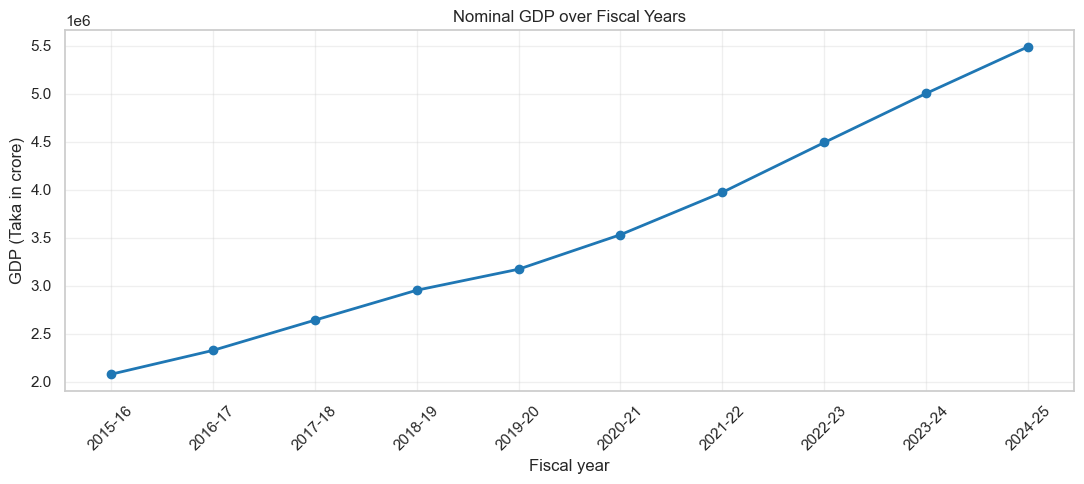

In [8]:
plt.figure(figsize=(11, 5))
plt.plot(model_data["FY_clean"], model_data["GDP"], marker="o", linewidth=2, color="tab:blue")
plt.title("Nominal GDP over Fiscal Years")
plt.xlabel("Fiscal year")
plt.ylabel("GDP (Taka in crore)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Inflation and CPI over fiscal years

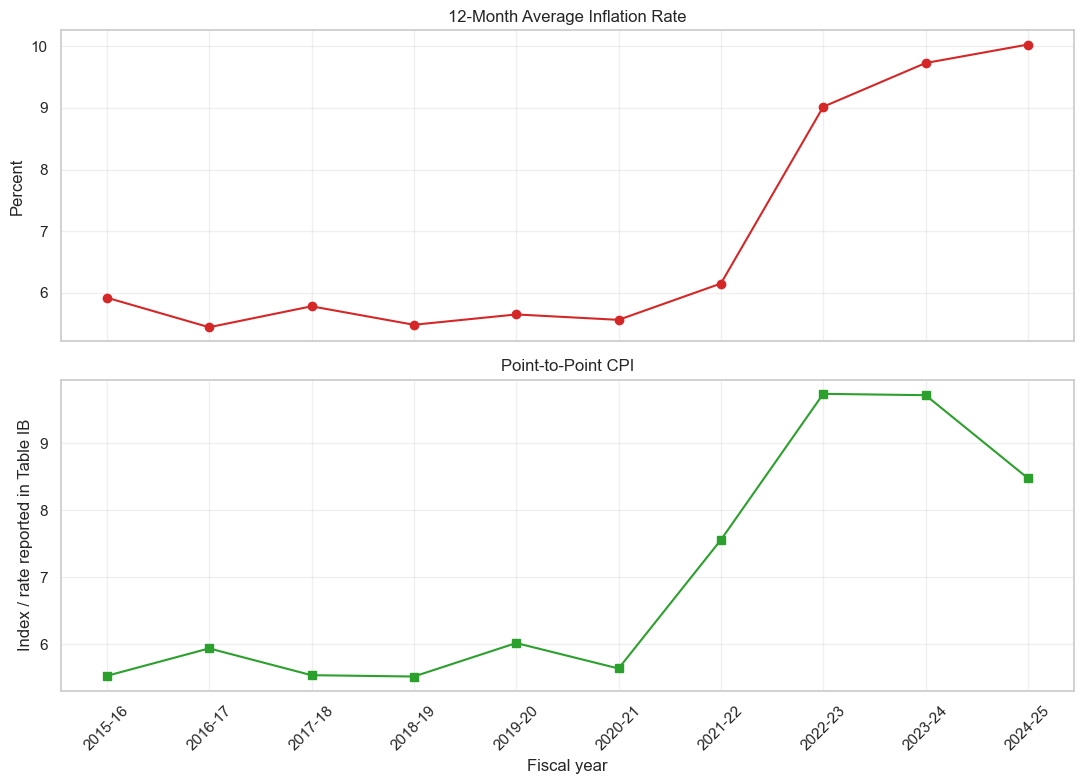

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(
    model_data["FY_clean"],
    model_data["Inflation_Rate"],
    marker="o",
    color="tab:red",
)
axes[0].set_title("12-Month Average Inflation Rate")
axes[0].set_ylabel("Percent")
axes[0].grid(alpha=0.3)

axes[1].plot(model_data["FY_clean"], model_data["CPI"], marker="s", color="tab:green")
axes[1].set_title("Point-to-Point CPI")
axes[1].set_xlabel("Fiscal year")
axes[1].set_ylabel("Index / rate reported in Table IB")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. GDP distribution and exports relationship

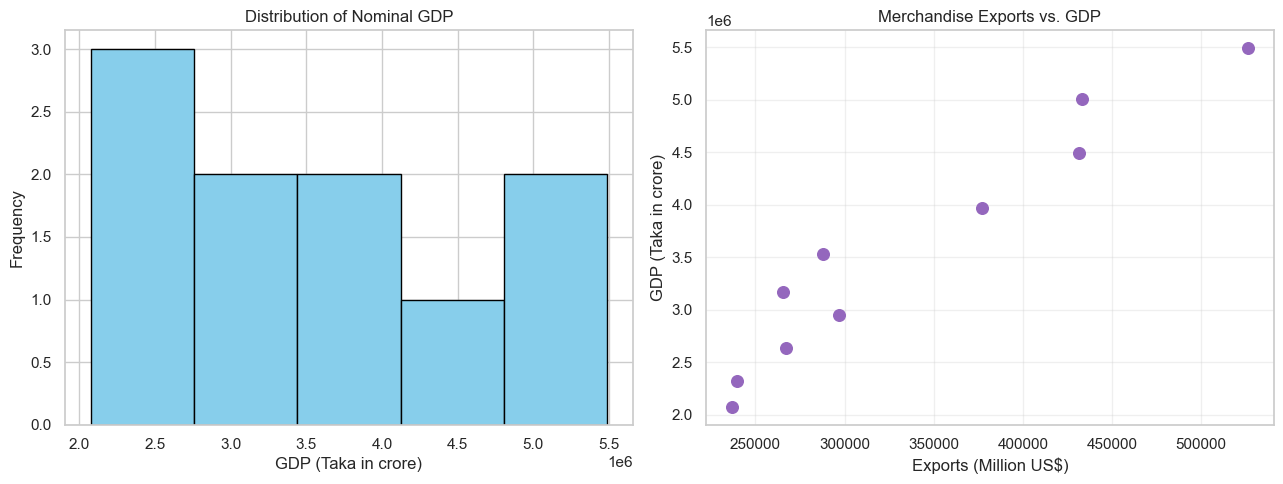

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(model_data["GDP"], bins=5, color="skyblue", edgecolor="black")
axes[0].set_title("Distribution of Nominal GDP")
axes[0].set_xlabel("GDP (Taka in crore)")
axes[0].set_ylabel("Frequency")

axes[1].scatter(model_data["Exports"], model_data["GDP"], color="tab:purple", s=70)
axes[1].set_title("Merchandise Exports vs. GDP")
axes[1].set_xlabel("Exports (Million US$)")
axes[1].set_ylabel("GDP (Taka in crore)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Correlation matrix

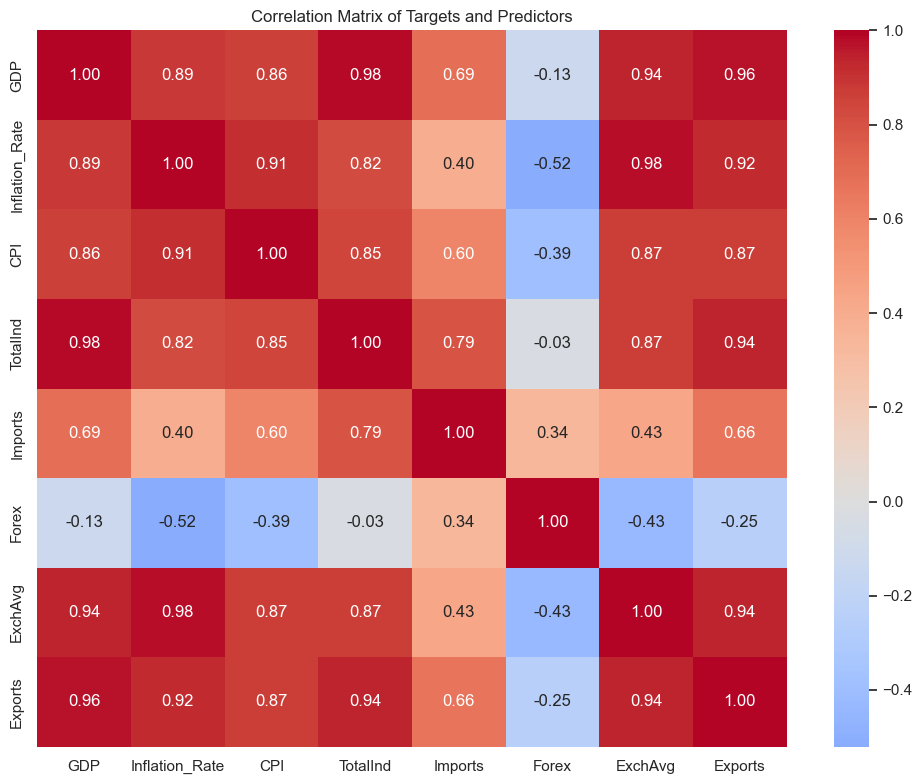

In [11]:
correlation_columns = [
    "GDP",
    "Inflation_Rate",
    "CPI",
    "TotalInd",
    "Imports",
    "Forex",
    "ExchAvg",
    "Exports",
]
correlation = model_data[correlation_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Matrix of Targets and Predictors")
plt.tight_layout()
plt.show()

# Baseline model comparison

The predictors are industrial production, imports, foreign-exchange reserves, the average exchange rate, and exports. GDP, inflation, and CPI are **not** used as predictors for one another. This prevents a model from using one outcome to predict another outcome in the same period.

The last two fiscal years are used as the test set so the evaluation reflects the chronological order of the data. KNN receives scaled features; the linear regression and decision tree use the original values.

Training fiscal years: ['2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23']
Testing fiscal years: ['2023-24', '2024-25']

Results for GDP


,Target,Model,MAE,RMSE,R2
0,GDP,Linear Regression,277208.354,283057.712,-0.356
1,GDP,Decision Tree,754914.700,793089.678,-9.644
2,GDP,KNN (k=3),1441089.367,1461449.142,-35.142


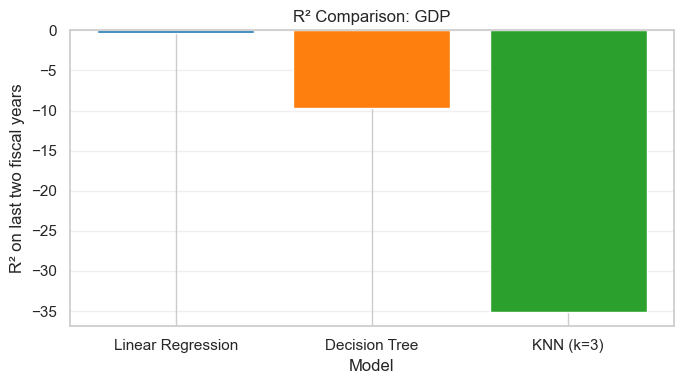


Results for Inflation_Rate


,Target,Model,MAE,RMSE,R2
0,Inflation_Rate,Linear Regression,1.881,2.063,-188.063
1,Inflation_Rate,Decision Tree,0.860,0.873,-32.871
2,Inflation_Rate,KNN (k=3),2.997,3.000,-399.112


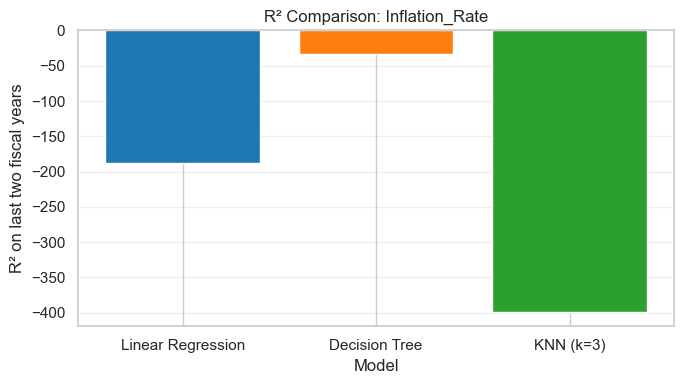


Results for CPI


,Target,Model,MAE,RMSE,R2
0,CPI,Linear Regression,3.038,3.691,-34.434
1,CPI,Decision Tree,0.640,0.891,-1.066
2,CPI,KNN (k=3),1.493,1.617,-5.801


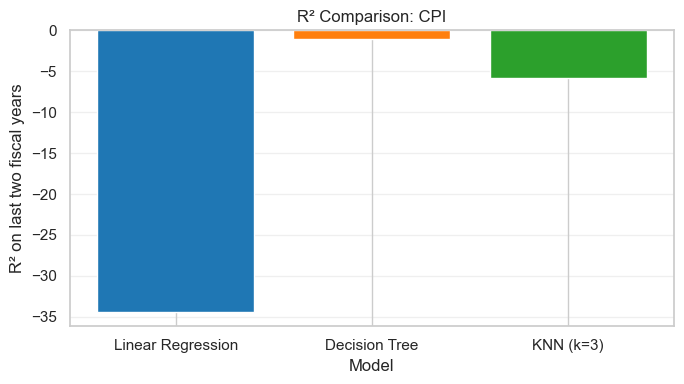

Combined baseline-model results


,Target,Model,MAE,RMSE,R2
0,GDP,Linear Regression,277208.354,283057.712,-0.356
1,GDP,Decision Tree,754914.700,793089.678,-9.644
2,GDP,KNN (k=3),1441089.367,1461449.142,-35.142
3,Inflation_Rate,Linear Regression,1.881,2.063,-188.063
4,Inflation_Rate,Decision Tree,0.860,0.873,-32.871
5,Inflation_Rate,KNN (k=3),2.997,3.000,-399.112
6,CPI,Linear Regression,3.038,3.691,-34.434
7,CPI,Decision Tree,0.640,0.891,-1.066
8,CPI,KNN (k=3),1.493,1.617,-5.801


In [12]:
targets = ["GDP", "Inflation_Rate", "CPI"]
feature_columns = ["TotalInd", "Imports", "Forex", "ExchAvg", "Exports"]

test_years = 2
if len(model_data) <= test_years + 3:
    raise ValueError("Not enough complete annual observations for the chosen train/test split.")

train_data = model_data.iloc[:-test_years]
test_data = model_data.iloc[-test_years:]

print("Training fiscal years:", train_data["FY_clean"].tolist())
print("Testing fiscal years:", test_data["FY_clean"].tolist())

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

all_results = []

for target in targets:
    y_train = train_data[target]
    y_test = test_data[target]

    models = {
        "Linear Regression": (LinearRegression(), X_train, X_test),
        "Decision Tree": (
            DecisionTreeRegressor(max_depth=3, random_state=42),
            X_train,
            X_test,
        ),
        "KNN (k=3)": (
            KNeighborsRegressor(n_neighbors=3),
            X_train_scaled,
            X_test_scaled,
        ),
    }

    target_results = []
    for model_name, (model, training_features, testing_features) in models.items():
        model.fit(training_features, y_train)
        predictions = model.predict(testing_features)

        target_results.append(
            {
                "Target": target,
                "Model": model_name,
                "MAE": mean_absolute_error(y_test, predictions),
                "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
                "R2": r2_score(y_test, predictions),
            }
        )

    target_results = pd.DataFrame(target_results)
    all_results.append(target_results)

    print(f"\nResults for {target}")
    display(target_results.round(3))

    plt.figure(figsize=(7, 4))
    plt.bar(
        target_results["Model"],
        target_results["R2"],
        color=["tab:blue", "tab:orange", "tab:green"],
    )
    plt.title(f"R² Comparison: {target}")
    plt.xlabel("Model")
    plt.ylabel("R² on last two fiscal years")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

model_results = pd.concat(all_results, ignore_index=True)
print("Combined baseline-model results")
display(model_results.round(3))

## Interpretation and next steps

- Treat the reported errors and R² values as descriptive only: the test set has just two fiscal years.
- The predictors are annual values from the same fiscal year, so this is a simple contemporaneous baseline, not a production-ready real-time nowcast.
- A stronger future version would require more historical observations and predictors available before the target period closes.
- Re-run the notebook when the workbook is updated; the cleaning rules intentionally select complete quarters and annual rows rather than fixed row ranges.

In [14]:
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()
targets = ["GDP", "Inflation_Rate", "CPI"]
feature_columns = ["TotalInd", "Imports", "Forex", "ExchAvg", "Exports"]

all_cv_results = []

for target in targets:
  X = model_data[feature_columns]
  y = model_data[target]

  # Evaluate models using Leave-One-Out Cross Validation across all 8 years
  models = {
      "Linear Regression": LinearRegression(),
      "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
      "KNN (k=2)": KNeighborsRegressor(n_neighbors=2),
  }

  for model_name, model in models.items():
    y_true_all, y_pred_all = [], []

    for train_idx, test_idx in loo.split(X):
      X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
      y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

      # Scale features
      scaler = StandardScaler()
      X_train_scaled = scaler.fit_transform(X_train)
      X_test_scaled = scaler.transform(X_test)

      # Fit and predict
      if "KNN" in model_name:
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
      else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

      y_true_all.append(y_test.values[0])
      y_pred_all.append(pred[0])

    # Compute overall metrics across all LOO folds
    mae = mean_absolute_error(y_true_all, y_pred_all)
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    r2 = r2_score(y_true_all, y_pred_all)

    all_cv_results.append({
        "Target": target,
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    })

cv_results_df = pd.DataFrame(all_cv_results)
print("Leave-One-Out Cross-Validation Results:")
display(cv_results_df.round(3))


Leave-One-Out Cross-Validation Results:


,Target,Model,MAE,RMSE,R2
0,GDP,Linear Regression,154397.916,191516.883,0.969
1,GDP,Decision Tree,556207.980,603594.404,0.695
2,GDP,KNN (k=2),287211.790,401320.297,0.865
3,Inflation_Rate,Linear Regression,0.715,0.955,0.720
4,Inflation_Rate,Decision Tree,0.376,0.457,0.936
5,Inflation_Rate,KNN (k=2),0.439,0.547,0.908
6,CPI,Linear Regression,1.233,1.827,-0.200
7,CPI,Decision Tree,0.667,1.023,0.624
8,CPI,KNN (k=2),0.537,0.652,0.847
